# GSM8K 深度–正确率评测：Qwen3-4B 的 thinking budget 实验

**模型**：`Qwen/Qwen3-4B` 原版（hybrid thinking，不是 `Qwen3-4B-Instruct-2507`）。
**数据**：GSM8K socratic 测试集 1319 题；深度 = gold solution 里 `<<...>>` 的个数（前面已经分好，本 notebook 不改）。
**条件**：5 个，每个条件单独写一个 jsonl。

| 条件 | thinking | vLLM `thinking_token_budget` |
|---|---|---|
| `thinking_off` | 关（`enable_thinking=False`） | — |
| `thinking_budget_256` | 开 | 128 |
| `thinking_budget_512` | 开 | 256 |
| `thinking_budget_1024` | 开 | 512 |
| `thinking_unlimited` | 开 | 不设（受 `max_tokens` 限制） |

**产物目录**：`gsm8k_result/Qwen3-4B/`（相对 notebook 所在目录）

- 逐题记录：`thinking_off.jsonl`、`thinking_budget_256.jsonl`、`thinking_budget_512.jsonl`、`thinking_budget_1024.jsonl`、`thinking_unlimited.jsonl`
- 汇总：`summary_overall.csv`、`summary_by_depth.csv`、`accuracy_by_depth.png`

**运行**：只需要改第二格的 `MODEL_PATH`。thinking budget 依赖 `ReasoningConfig` + `SamplingParams(thinking_token_budget=...)`，需要较新的 vLLM。

In [1]:
# ===== 全局配置：只需要改 MODEL_PATH =====
import os, re, json, time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# 本地 Qwen3-4B 权重目录（Qwen/Qwen3-4B 原版），改成自己的路径
MODEL_PATH = "../models/Qwen3-4B"

SPLIT = "test"

# 采样参数沿用项目统一值；thinking 不限制时要留足输出长度
TEMPERATURE = 0.6
TOP_P = 0.95
SEED = 0
MAX_NEW_TOKENS = 8192
MAX_MODEL_LEN = 16384

# 结果全部写到 gsm8k_result/Qwen3-4B/，每个条件一个 jsonl
RESULTS_DIR = Path.cwd() / "gsm8k_result" / "Qwen3-4B"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 数据目录：向上找到含 gsm8k_dataset 的仓库根
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "gsm8k_dataset").exists())
DATA_DIR = ROOT / "gsm8k_dataset"

# 五个条件：thinking 关闭 / thinking 打开 + budget 256、512、1024 / 不限制
CONDITIONS = [
    {"name": "thinking_off", "thinking": False, "budget": None},
    {"name": "thinking_budget_128", "thinking": True, "budget": 128},
    {"name": "thinking_budget_256", "thinking": True, "budget": 256},
    {"name": "thinking_budget_512", "thinking": True, "budget": 512},
    {"name": "thinking_unlimited", "thinking": True, "budget": None},
]

print("模型:", MODEL_PATH)
print("数据:", DATA_DIR)
print("结果:", RESULTS_DIR)
print("条件:", [c["name"] for c in CONDITIONS])

模型: ../models/Qwen3-4B
数据: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/gsm8k_dataset
结果: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/gsm8k_result/Qwen3-4B
条件: ['thinking_off', 'thinking_budget_128', 'thinking_budget_256', 'thinking_budget_512', 'thinking_unlimited']


## 1. 数据与深度（保持不变）

深度直接由 gold answer 里的 `<<...>>` 数量得到，不依赖模型输出。

In [2]:
# ===== 读取 GSM8K socratic 测试集，并按 <<...>> 计算深度 =====
ANN_RE = re.compile(r"<<[^<>]*>>")


def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def load_gsm8k(split="test"):
    local = DATA_DIR / f"{split}.jsonl"
    if local.exists():
        return pd.DataFrame(read_jsonl(local)), f"local socratic ({local.name})"
    from datasets import load_dataset
    ds = load_dataset("openai/gsm8k", "socratic", split=split)
    df = ds.to_pandas()
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    df.to_json(local, orient="records", lines=True, force_ascii=False)
    return df, "huggingface openai/gsm8k[socratic]"


raw_df, source = load_gsm8k(SPLIT)
df = raw_df.reset_index(drop=True)
df["uid"] = [f"{SPLIT}-{i:04d}" for i in range(len(df))]
df["depth"] = df["answer"].map(lambda s: len(ANN_RE.findall(str(s))))

print(f"数据来源: {source} | 题数: {len(df)}")
print(df[["question", "depth"]].head(3).to_string(index=False, max_colwidth=60))

dist = (df["depth"].value_counts().sort_index()
          .rename_axis("深度").reset_index(name="题数"))
dist["占比"] = dist["题数"] / len(df)
print("\n深度分布：")
display(dist.style.format({"占比": "{:.1%}"}))

数据来源: local socratic (test.jsonl) | 题数: 1319
                                                    question  depth
Janet’s ducks lay 16 eggs per day. She eats three for bre...      2
A robe takes 2 bolts of blue fiber and half that much whi...      2
Josh decides to try flipping a house.  He buys a house fo...      4

深度分布：


,深度,题数,占比
0,0,18,1.4%
1,1,65,4.9%
2,2,357,27.1%
3,3,364,27.6%
4,4,290,22.0%
5,5,138,10.5%
6,6,57,4.3%
7,7,21,1.6%
8,8,9,0.7%


## 2. Prompt 与答案解析

Prompt 直接走模型自带的 chat template：`enable_thinking=False` 时模板会预填一个空的 `<think></think>` 块，模型直接写答案；`True` 时模型自己生成 `<think> ... </think>`。

答案解析：gold 取 `####` 后的数字；预测优先取最后一个 `####`，其次 `\boxed{}`，最后取全文最后一个数字。

In [3]:
# ===== Prompt 与答案抽取 =====
SYSTEM_PROMPT = """You are a math problem solver. Solve the problem carefully step by step.

Your response MUST be exactly in this format:
#### <numeric answer>

where <numeric answer> is a single number (no units, no commas, no extra words). Do not write anything after the #### line.

No extra lines should appear in your response.
"""

NUM_RE = re.compile(r"-?\d[\d,]*(?:\.\d+)?")


def build_messages(question, thinking=True):
    if thinking:
        return [
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": question},
               ]
    return [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": question},
            {"role": "assistant", "content": "#### "}
           ]


def parse_number(text):
    """从一段文字里取最后一个数字；支持 $、逗号、Unicode 负号。"""
    if text is None:
        return None
    s = str(text).replace("−", "-").replace("$", "").replace("，", ",")
    nums = NUM_RE.findall(s)
    if not nums:
        return None
    try:
        return float(nums[-1].replace(",", ""))
    except ValueError:
        return None


def parse_gold(answer):
    """GSM8K gold：#### 后面的数字。"""
    s = str(answer)
    if "####" in s:
        return parse_number(s.rsplit("####", 1)[1])
    return parse_number(s.strip().splitlines()[-1])


def parse_pred(text):
    """模型输出：优先取最后一个 #### 行，其次 \boxed{}，最后取全文最后一个数。"""
    text = str(text).replace("<|im_end|>", "")
    if "####" in text:
        return parse_number(text.rsplit("####", 1)[1])
    m = re.search(r"\\boxed\{([^}]*)\}", text)
    if m:
        return parse_number(m.group(1))
    return parse_number(text)


def is_correct(pred, gold, tol=1e-4):
    return pred is not None and gold is not None and abs(pred - gold) <= tol


df["gold"] = df["answer"].map(parse_gold)
print("gold 解析失败:", int(df["gold"].isna().sum()))

gold 解析失败: 0


## 3. vLLM 推理（thinking budget）

`LLM` 只加载一次，`reasoning_config` 告诉 vLLM 思考块从哪开始、到哪结束：

- 起点：`<|im_start|>assistant\n`（prompt 的结尾）
- 终点：`</think>\n\n`

每个条件一个 `SamplingParams`：`thinking_token_budget` 设成 256 / 512 / 1024，或者 `None`（不限制）。
预算用完时 vLLM 会强制模型输出 `</think>`，然后继续生成正式答案。

> 显存不够时调小 `MAX_MODEL_LEN` 或 `gpu_memory_utilization`；T4 等 Turing 卡把 `dtype` 改成 `"half"`。

In [4]:
# ===== 用 vLLM 跑五个条件，每个条件一个 jsonl =====
os.environ.setdefault("VLLM_USE_FLASHINFER_SAMPLER", "0")  # 没有 nvcc 时避免 FlashInfer 采样器 JIT 失败

from vllm import LLM, SamplingParams
from vllm.config import ReasoningConfig

llm = LLM(
    model=MODEL_PATH,
    dtype="bfloat16",
    gpu_memory_utilization=0.85,
    max_model_len=MAX_MODEL_LEN,
    reasoning_config=ReasoningConfig(
        reasoning_start_str="<|im_start|>assistant\n",
        reasoning_end_str="</think>\n\n",
    ),
)
tokenizer = llm.get_tokenizer()

W1112 19:08:40.993000 137193 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1112 19:08:40.994000 137193 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1112 19:08:40.995000 137193 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(MainProcess pid=137193) INFO 11-12 19:08:43 [startup.py:96] non-default args: {'dtype': 'bfloat16', 'max_model_len': 16384, 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'reasoning_config': ReasoningConfig(reasoning_parser='', reasoning_start_str='<|im_start|>assistant\n', reasoning_end_str='</think>\n\n'), 'model': '../models/Qwen3-4B'}
(MainProcess pid=137193) INFO 11-12 19:08:43 [model.py:744] Resolved architecture: Qwen3ForCausalLM
(MainProcess pid=137193) INFO 11-12 19:08:43 [model.py:2170] Using max model len 16384
(MainProcess pid=137193) INFO 11-12 19:08:43 [scheduler.py:310] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=137193) INFO 11-12 19:08:43 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(EngineCore pid=137919) INFO 11-12 19:08:44 [core.py:139] Initializing a V1 LLM engine (v0.33.0) with conf

Loading safetensors checkpoint shards:   0% Completed | 0/3 [00:00<?, ?it/s]


(EngineCore pid=137919) INFO 11-12 19:08:47 [default_loader.py:506] Loading weights took 0.65 seconds
(EngineCore pid=137919) INFO 11-12 19:08:48 [model_runner.py:428] Model loading took 7.56 GiB memory and 2.541384 seconds
(EngineCore pid=137919) INFO 11-12 19:08:48 [topk_topp_sampler.py:121] FlashInfer top-p/top-k sampling disabled via VLLM_USE_FLASHINFER_SAMPLER=0.
(EngineCore pid=137919) INFO 11-12 19:08:48 [torch_utils.py:281] Reducing Torch threads from 16 to 1 for serving. Set OMP_NUM_THREADS in the external environment to override.
(EngineCore pid=137919) INFO 11-12 19:08:48 [utils.py:381] Using LBNHC KV cache layout.
(EngineCore pid=137919) INFO 11-12 19:08:49 [caching.py:342] reconstructed serializable fn from standalone compile artifacts. num_artifacts=3 num_submods=37
(EngineCore pid=137919) INFO 11-12 19:08:49 [decorators.py:326] [backbone] Directly load AOT compilation from path /home/ubuntu-user/.cache/vllm/torch_compile_cache/torch_aot_compile/8e3666c503856d0560ccc747a7

Capturing CUDA graphs (FULL): 100%|██████████████| 2/2 [00:00<00:00, 38.83it/s]


(EngineCore pid=137919) INFO 11-12 19:08:53 [model_runner.py:1163] Graph capturing finished in 3 secs, took 0.38 GiB
(EngineCore pid=137919) INFO 11-12 19:08:53 [gpu_worker.py:772] Available KV cache memory: 11.23 GiB
(EngineCore pid=137919) INFO 11-12 19:08:53 [gpu_worker.py:787] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.8500 is equivalent to --gpu-memory-utilization=0.8315 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.8685. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=137919) INFO 11-12 19:08:53 [kv_cache_utils.py:1147] GPU KV cache size: 81,760 tokens, Maximum concurrency for 16,384 tokens per request: 4.99x
(EngineCore pid=137919) INFO 11-12 19:08:53 [kernel_warmup.py:179] JIT kernel warmup starting.
(EngineCore pid=137919) INFO 11-12 19:08:53 [kernel_warmup.py:192] JIT kernel warmup finished in 0.00s.


Capturing CUDA graphs (FULL): 100%|████████████| 35/35 [00:00<00:00, 49.15it/s]


(EngineCore pid=137919) INFO 11-12 19:08:57 [model_runner.py:1163] Graph capturing finished in 3 secs, took 0.22 GiB
(EngineCore pid=137919) INFO 11-12 19:08:57 [gpu_worker.py:1003] CUDA graph pool memory: 0.22 GiB (actual), 0.44 GiB (estimated), difference: 0.21 GiB (93.9%).
(EngineCore pid=137919) INFO 11-12 19:08:57 [gpu_worker.py:1066] Free memory on device (22.57/23.51 GiB) on startup. Desired GPU memory utilization is (0.85, 19.98 GiB). Actual usage is 7.8 GiB for consumed memory (weights + non-torch), 0.95 GiB for peak activation, and 0.22 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=11658949120` (10.86 GiB) to fit into requested memory, or `--kv-cache-memory=14437446144` (13.45 GiB) to fully utilize gpu memory. Current kv cache memory in use is 11.23 GiB.
(EngineCore pid=137919) INFO 11-12 19:08:57 [jit_monitor.py:84] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=137919) I

In [ ]:
# 两种模式的 prompt 各准备一份，五个条件复用
# add_generation_prompt 与 continue_final_message 互斥，按 thinking 分支只让一个为 True
def prompt_kwargs(thinking):
    if thinking:
        # 思考模式：追加生成提示，让模型自己写  thinking...</think>
        return {
            "add_generation_prompt": True,
            "continue_final_message": False,
            "enable_thinking": True,
        }
    # 非思考模式：build_messages 已预填充 "#### "，续写该 assistant 消息，逼模型直接给最终答案
    return {
        "add_generation_prompt": False,
        "continue_final_message": True,
        "enable_thinking": False,
    }


prompts = {
    thinking: [tokenizer.apply_chat_template(
                   build_messages(q, thinking), tokenize=False,
                   **prompt_kwargs(thinking))
               for q in df["question"]]
    for thinking in (True, False)
}

records = df.to_dict("records")

for cond in CONDITIONS:
    name = cond["name"]
    path = RESULTS_DIR / f"{name}.jsonl"

    sp = SamplingParams(
        temperature=TEMPERATURE,
        top_p=TOP_P,
        max_tokens=MAX_NEW_TOKENS,
        seed=SEED,
        thinking_token_budget=cond["budget"],  # None = 不限制
    )

    t0 = time.time()
    outputs = llm.generate(prompts[cond["thinking"]], sp)
    elapsed = time.time() - t0

    rows = []
    for r, out in zip(records, outputs):
        text = out.outputs[0].text
        pred = parse_pred(text)
        rows.append({
            "condition": name,
            "thinking": cond["thinking"],
            "thinking_budget": cond["budget"],
            "uid": r["uid"],
            "depth": int(r["depth"]),
            "gold": r["gold"],
            "pred": pred,
            "correct": bool(is_correct(pred, r["gold"])),
            "n_tokens": len(out.outputs[0].token_ids),
            "finish_reason": out.outputs[0].finish_reason,
            "output": text,
        })

    with open(path, "w", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")

    acc = sum(row["correct"] for row in rows) / len(rows)
    avg_tok = sum(row["n_tokens"] for row in rows) / len(rows)
    print(f"{name}: acc={acc:.2%} | 平均 {avg_tok:.0f} tokens | 用时 {elapsed / 60:.1f} min -> {path}")

## 4. 汇总

In [5]:
# ===== 总体正确率 + 按深度 =====
dfs = {c["name"]: pd.DataFrame(read_jsonl(RESULTS_DIR / f"{c['name']}.jsonl")) for c in CONDITIONS}

overall = pd.DataFrame([{
    "condition": name,
    "n": len(r),
    "correct": int(r["correct"].sum()),
    "acc": r["correct"].mean(),
    "avg_tokens": r["n_tokens"].mean(),
    "truncated": r["finish_reason"].eq("length").mean(),
} for name, r in dfs.items()])
print(overall.to_string(index=False))
overall.to_csv(RESULTS_DIR / "summary_overall.csv", index=False, encoding="utf-8-sig")

by_depth = pd.DataFrame({name: r.groupby("depth")["correct"].mean() for name, r in dfs.items()})
n_by_depth = next(iter(dfs.values())).groupby("depth").size().rename("题数")
print("\n按深度分组的正确率：")
print(pd.concat([n_by_depth, by_depth], axis=1).to_string())
by_depth.to_csv(RESULTS_DIR / "summary_by_depth.csv", encoding="utf-8-sig")

          condition    n  correct      acc  avg_tokens  truncated
       thinking_off 1319      162 0.122820    4.521607   0.000000
thinking_budget_128 1319      569 0.431387  232.945413   0.006065
thinking_budget_256 1319      920 0.697498  288.959818   0.000758
thinking_budget_512 1319     1139 0.863533  431.145565   0.000000
 thinking_unlimited 1319     1237 0.937832  751.294920   0.001516

按深度分组的正确率：
        题数  thinking_off  thinking_budget_128  thinking_budget_256  thinking_budget_512  thinking_unlimited
depth                                                                                                      
0       18      0.111111             0.555556             0.833333             0.777778            0.888889
1       65      0.215385             0.430769             0.692308             0.846154            0.953846
2      357      0.226891             0.655462             0.876751             0.935574            0.971989
3      364      0.109890             0.414835       

## 5. 正确率–深度图

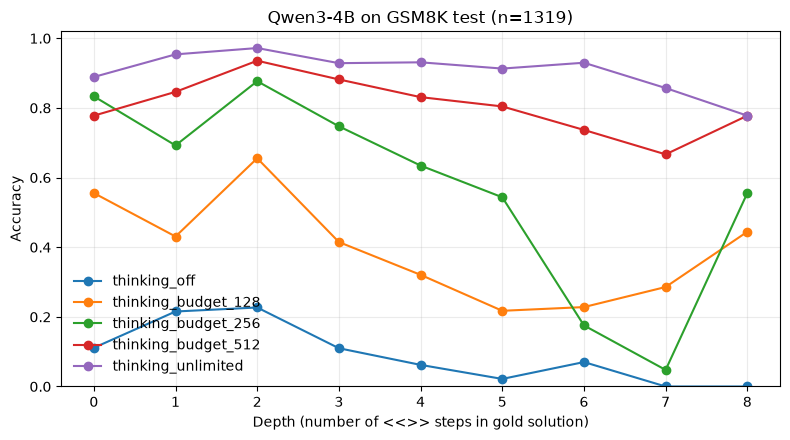

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, r in dfs.items():
    g = r.groupby("depth")["correct"].mean()
    ax.plot(g.index, g.values, marker="o", label=name)
ax.set_xlabel("Depth (number of <<>> steps in gold solution)")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.02)
ax.set_xticks(sorted(n_by_depth.index))
ax.grid(alpha=0.25)
ax.legend(frameon=False)
ax.set_title(f"Qwen3-4B on GSM8K {SPLIT} (n={len(df)})")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "accuracy_by_depth.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. 注意事项

1. **thinking 预算是硬限制**：到预算后 vLLM 强制输出 `</think>`，思考被截断，答案质量可能下降；这正是要测的东西。
2. **`thinking_unlimited` 不是真的无限**：仍受 `MAX_NEW_TOKENS=8192` 和 `MAX_MODEL_LEN=16384` 限制。`finish_reason == "length"` 比例高就调大这两个值（同时看显存）。
3. **单次采样**：`temperature=0.6` 沿项目统一值，重跑会有波动；要更稳可以改成 0 做贪心。
4. **base 模型指令遵循较弱**：没写 `####` 的样本会退化成「最后一个数字」，错误样例直接看 jsonl 里的 `output` 原文。

In [5]:
# ===== 续跑 thinking_unlimited：截掉已写出的 </think>，追加 "wait " 让模型继续思考 =====
prev = pd.DataFrame(read_jsonl(RESULTS_DIR / "thinking_unlimited.jsonl"))
prev = prev.merge(df[["uid", "question"]], on="uid", how="left")


def wait_prompt(row):
    # 只保留 </think> 之前的思考内容，丢弃已给出的正式答案
    thinking = str(row["output"]).split("</think>", 1)[0].rstrip()
    messages = build_messages(row["question"], thinking=True) + [
        {"role": "assistant", "content": thinking + " wait "}
    ]
    return tokenizer.apply_chat_template(
        messages, tokenize=False,
        add_generation_prompt=False, continue_final_message=True,
        enable_thinking=True)


prev_rows = prev.to_dict("records")
wait_prompts = [wait_prompt(r) for r in prev_rows]

sp_wait = SamplingParams(
    temperature=TEMPERATURE,
    top_p=TOP_P,
    max_tokens=MAX_NEW_TOKENS,
    seed=SEED,
    thinking_token_budget=None,  # 同样不限制
)

t0 = time.time()
outputs_wait = llm.generate(wait_prompts, sp_wait)
elapsed = time.time() - t0

rows = []
for r, out in zip(prev_rows, outputs_wait):
    text = out.outputs[0].text
    pred = parse_pred(text)
    rows.append({
        "condition": "thinking_unlimited_wait",
        "uid": r["uid"],
        "depth": int(r["depth"]),
        "gold": r["gold"],
        "pred": pred,
        "correct": bool(is_correct(pred, r["gold"])),
        "n_tokens": len(out.outputs[0].token_ids),
        "finish_reason": out.outputs[0].finish_reason,
        "output": text,
    })

path = RESULTS_DIR / "thinking_unlimited_wait.jsonl"
with open(path, "w", encoding="utf-8") as f:
    for row in rows:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

new = pd.DataFrame(rows)
print(f"thinking_unlimited      : acc={prev['correct'].mean():.2%} | 平均 {prev['n_tokens'].mean():.0f} tokens")
print(f"thinking_unlimited_wait : acc={new['correct'].mean():.2%} | 平均 {new['n_tokens'].mean():.0f} tokens | 用时 {elapsed/60:.1f} min -> {path}")
print("\n按深度对比：")
print(pd.DataFrame({
    "prev": prev.groupby("depth")["correct"].mean(),
    "wait": new.groupby("depth")["correct"].mean(),
}).to_string())

Rendering prompts:   0%|          | 0/1319 [00:00<?, ?it/s]

Processed prompts: 100%|█| 1319/1319 [12:21<00:00,  1.78it/s, est. speed input:

thinking_unlimited      : acc=93.78% | 平均 751 tokens
thinking_unlimited_wait : acc=92.80% | 平均 350 tokens | 用时 12.4 min -> /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/gsm8k_result/Qwen3-4B/thinking_unlimited_wait.jsonl

按深度对比：
           prev      wait
depth                    
0      0.888889  0.833333
1      0.953846  0.938462
2      0.971989  0.955182
3      0.928571  0.925824
4      0.931034  0.917241
5      0.913043  0.913043
6      0.929825  0.912281
7      0.857143  0.904762
8      0.777778  0.777778
